In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path(
    r"C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING"
)

MODELS = PROJECT_ROOT / "models"
MODELS.mkdir(exist_ok=True)

print("Project:", PROJECT_ROOT)
print("Models folder:", MODELS)

Project: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING
Models folder: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\models


In [2]:
ROWS, COLS = 4, 4

START = (0, 0)
GOAL = (3, 3)
TRAP = (1, 3)

ACTIONS = [
    (-1, 0),   # Up
    (1, 0),    # Down
    (0, -1),   # Left
    (0, 1),    # Right
]

ACTION_NAMES = ["up", "down", "left", "right"]

# Plot coordinates: positive y points downward in imshow.
PLOT_ARROWS = [
    (0, -1),
    (0, 1),
    (-1, 0),
    (1, 0),
]


def step(state, action, step_cost=-0.04, trap=TRAP):
    """Return the next state, reward, and termination flag."""
    r, c = state
    dr, dc = ACTIONS[action]

    next_state = (
        min(max(r + dr, 0), ROWS - 1),
        min(max(c + dc, 0), COLS - 1),
    )

    if next_state == GOAL:
        return next_state, 1.0, True

    if next_state == trap:
        return next_state, -1.0, True

    return next_state, step_cost, False


print("Start:", START)
print("Goal:", GOAL)
print("Trap:", TRAP)
print("Ordinary move reward: -0.04")
print("Goal reward: +1")
print("Trap reward: -1")
print("A move beyond a boundary leaves the position unchanged.")

Start: (0, 0)
Goal: (3, 3)
Trap: (1, 3)
Ordinary move reward: -0.04
Goal reward: +1
Trap reward: -1
A move beyond a boundary leaves the position unchanged.


In [3]:
def train_q_learning(
    episodes=5000,
    alpha=0.15,
    gamma=0.95,
    epsilon_start=1.0,
    min_epsilon=0.05,
    epsilon_decay=0.9985,
    step_cost=-0.04,
    trap=TRAP,
    seed=42,
):
    rng = np.random.default_rng(seed)

    Q_table = np.zeros((ROWS, COLS, len(ACTIONS)))
    epsilon = epsilon_start

    training_returns = []
    epsilon_history = []

    for episode in range(episodes):
        state = START
        episode_return = 0.0

        epsilon_history.append(epsilon)

        for _ in range(100):
            if rng.random() < epsilon:
                action = int(rng.integers(len(ACTIONS)))
            else:
                action = int(np.argmax(Q_table[state]))

            next_state, reward, done = step(
                state,
                action,
                step_cost=step_cost,
                trap=trap,
            )

            episode_return += reward

            # Terminal states have no future reward term.
            if done:
                target = reward
            else:
                target = (
                    reward
                    + gamma * np.max(Q_table[next_state])
                )

            Q_table[state][action] += alpha * (
                target - Q_table[state][action]
            )

            state = next_state

            if done:
                break

        training_returns.append(episode_return)

        epsilon = max(
            min_epsilon,
            epsilon * epsilon_decay,
        )

    return (
        Q_table,
        np.asarray(training_returns),
        np.asarray(epsilon_history),
        epsilon,
    )


Q, training_returns, epsilon_history, final_epsilon = (
    train_q_learning()
)

print("Training complete.")
print("Episodes:", len(training_returns))
print("Q-table shape:", Q.shape)
print("Final exploration rate:", round(final_epsilon, 4))

print("\nQ-values at the starting cell:")
for name, value in zip(ACTION_NAMES, Q[START]):
    print(f"{name:>5}: {value:.6f}")

Training complete.
Episodes: 5000
Q-table shape: (4, 4, 4)
Final exploration rate: 0.05

Q-values at the starting cell:
   up: 0.523165
 down: 0.592806
 left: 0.523165
right: 0.592806


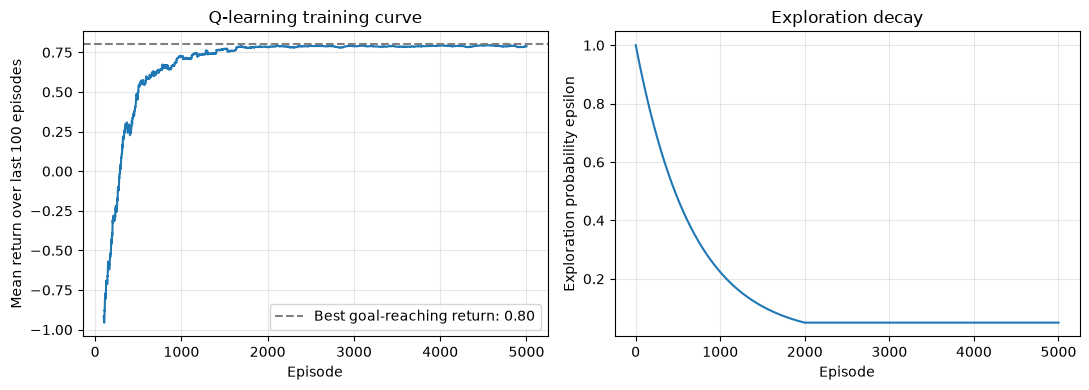

In [4]:
window = 100

moving_returns = np.convolve(
    training_returns,
    np.ones(window) / window,
    mode="valid",
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(
    np.arange(window, len(training_returns) + 1),
    moving_returns,
)

axes[0].axhline(
    0.80,
    linestyle="--",
    color="gray",
    label="Best goal-reaching return: 0.80",
)

axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Mean return over last 100 episodes")
axes[0].set_title("Q-learning training curve")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    np.arange(1, len(epsilon_history) + 1),
    epsilon_history,
)

axes[1].set_xlabel("Episode")
axes[1].set_ylabel("Exploration probability epsilon")
axes[1].set_title("Exploration decay")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
def evaluate_policy(
    Q_table,
    episodes=200,
    step_cost=-0.04,
    trap=TRAP,
):
    successes = 0
    returns = []
    lengths = []
    example_path = None

    for episode in range(episodes):
        state = START
        total = 0.0
        path = [state]

        for move in range(1, 101):
            action = int(np.argmax(Q_table[state]))

            state, reward, done = step(
                state,
                action,
                step_cost=step_cost,
                trap=trap,
            )

            total += reward
            path.append(state)

            if done:
                successes += int(state == GOAL)
                break

        returns.append(total)
        lengths.append(move)

        if episode == 0:
            example_path = path

    return {
        "episodes": episodes,
        "success_rate": successes / episodes,
        "mean_return": float(np.mean(returns)),
        "return_std": float(np.std(returns)),
        "mean_moves": float(np.mean(lengths)),
        "path": example_path,
    }


baseline_results = evaluate_policy(Q)

print("Evaluation episodes:", baseline_results["episodes"])
print("Exploration during evaluation: OFF")
print("Success rate:", f"{baseline_results['success_rate']:.1%}")
print("Mean return:", round(baseline_results["mean_return"], 3))
print("Return standard deviation:", baseline_results["return_std"])
print("Mean moves:", baseline_results["mean_moves"])

print(
    "Learned action at start:",
    ACTION_NAMES[int(np.argmax(Q[START]))],
)

print("\nExample greedy route:")
print(" -> ".join(map(str, baseline_results["path"])))

Evaluation episodes: 200
Exploration during evaluation: OFF
Success rate: 100.0%
Mean return: 0.8
Return standard deviation: 0.0
Mean moves: 6.0
Learned action at start: down

Example greedy route:
(0, 0) -> (1, 0) -> (2, 0) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)


In [6]:
q_path = MODELS / "gridworld_q_table.npy"

np.save(q_path, Q)
Q_loaded = np.load(q_path)

assert np.array_equal(Q, Q_loaded), (
    "Reloaded Q-table differs from the original."
)

policy = np.full((ROWS, COLS), "", dtype=object)

for r in range(ROWS):
    for c in range(COLS):
        state = (r, c)

        if state == GOAL:
            policy[r, c] = "GOAL"
        elif state == TRAP:
            policy[r, c] = "TRAP"
        else:
            policy[r, c] = ACTION_NAMES[
                int(np.argmax(Q_loaded[state]))
            ]

print("Saved model:", q_path)
print("File exists:", q_path.exists())
print("Reload verification passed.")

print("\nPolicy from the reloaded table:")
for row in policy:
    print(" | ".join(f"{action:^7}" for action in row))

loaded_results = evaluate_policy(Q_loaded)

print(
    "\nReloaded policy success rate:",
    f"{loaded_results['success_rate']:.1%}",
)

print(
    "Reloaded policy mean return:",
    round(loaded_results["mean_return"], 3),
)

Saved model: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\models\gridworld_q_table.npy
File exists: True
Reload verification passed.

Policy from the reloaded table:
 down   |  down   |  down   |  left  
 down   |  down   |  down   |  TRAP  
 right  |  down   |  down   |  down  
 right  |  right  |  right  |  GOAL  

Reloaded policy success rate: 100.0%
Reloaded policy mean return: 0.8


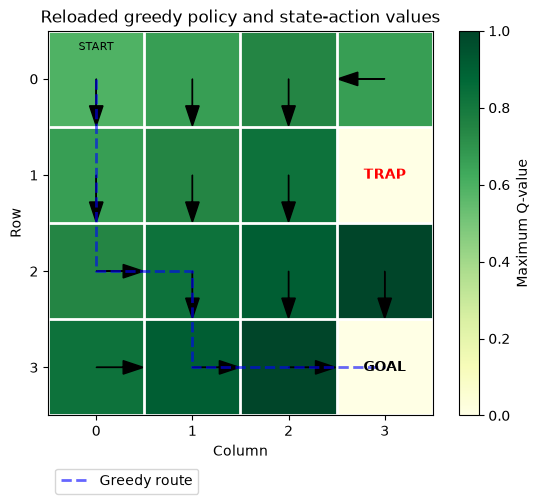

In [7]:
def plot_policy(Q_table, title, trap=TRAP, path=None):
    values = Q_table.max(axis=2)

    fig, ax = plt.subplots(figsize=(6, 5))

    heatmap = ax.imshow(values, cmap="YlGn")
    fig.colorbar(
        heatmap,
        ax=ax,
        label="Maximum Q-value",
    )

    if path is not None:
        ax.plot(
            [state[1] for state in path],
            [state[0] for state in path],
            color="blue",
            linestyle="--",
            linewidth=2,
            alpha=0.6,
            label="Greedy route",
        )
        ax.legend(loc="upper left", bbox_to_anchor=(0, -0.12))

    for r in range(ROWS):
        for c in range(COLS):
            state = (r, c)

            if state == GOAL:
                ax.text(
                    c, r, "GOAL",
                    ha="center",
                    va="center",
                    fontweight="bold",
                )
            elif state == trap:
                ax.text(
                    c, r, "TRAP",
                    ha="center",
                    va="center",
                    color="red",
                    fontweight="bold",
                )
            else:
                action = int(np.argmax(Q_table[state]))
                dx, dy = PLOT_ARROWS[action]

                ax.arrow(
                    c, r,
                    0.28 * dx,
                    0.28 * dy,
                    head_width=0.14,
                    color="black",
                )

                if state == START:
                    ax.text(
                        c, r - 0.30,
                        "START",
                        ha="center",
                        fontsize=8,
                    )

    ax.set_xticks(range(COLS))
    ax.set_yticks(range(ROWS))
    ax.set_xlabel("Column")
    ax.set_ylabel("Row")

    ax.set_xticks(np.arange(-0.5, COLS, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, ROWS, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)

    ax.set_title(title)

    plt.tight_layout()
    plt.show()


plot_policy(
    Q_loaded,
    "Reloaded greedy policy and state-action values",
    path=loaded_results["path"],
)

## Experiment Prediction

I will change the ordinary step cost from -0.04 to -0.10,
keeping the other training settings unchanged.

I predict that a shortest safe route to the goal will remain optimal.
Each additional ordinary move becomes more costly, so unnecessary
movement is penalized more strongly.

A six-move goal-reaching route should earn:

5(-0.10) + 1 = 0.50

The exact selected route may change because several shortest safe
routes exist. I expect lower learned values and a lower undiscounted
return, rather than necessarily a different route length.

Changed step cost: -0.1
Success rate: 100.0%
Mean return: 0.5
Mean moves: 6.0

Changed greedy route:
(0, 0) -> (0, 1) -> (1, 1) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)


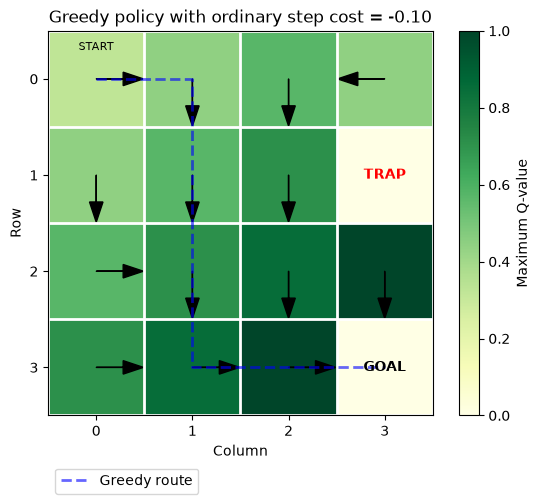

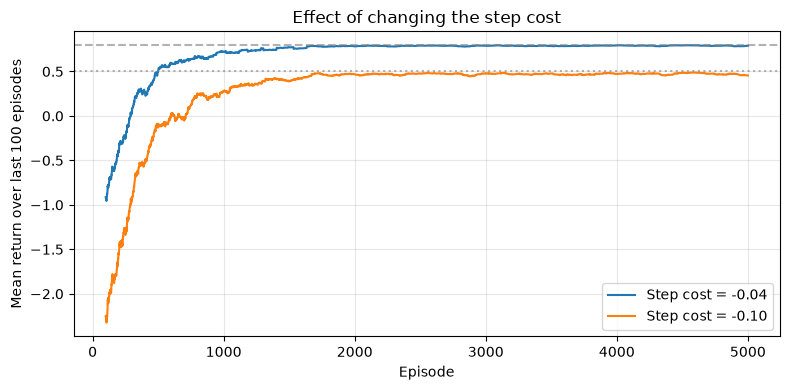

In [8]:
CHANGED_STEP_COST = -0.10

(
    Q_changed,
    changed_training_returns,
    changed_epsilon_history,
    changed_final_epsilon,
) = train_q_learning(step_cost=CHANGED_STEP_COST)

changed_results = evaluate_policy(
    Q_changed,
    step_cost=CHANGED_STEP_COST,
)

print("Changed step cost:", CHANGED_STEP_COST)
print("Success rate:", f"{changed_results['success_rate']:.1%}")
print("Mean return:", round(changed_results["mean_return"], 3))
print("Mean moves:", changed_results["mean_moves"])

print("\nChanged greedy route:")
print(" -> ".join(map(str, changed_results["path"])))

plot_policy(
    Q_changed,
    "Greedy policy with ordinary step cost = -0.10",
    path=changed_results["path"],
)

changed_moving = np.convolve(
    changed_training_returns,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(window, len(training_returns) + 1),
    moving_returns,
    label="Step cost = -0.04",
)

plt.plot(
    np.arange(window, len(changed_training_returns) + 1),
    changed_moving,
    label="Step cost = -0.10",
)

plt.axhline(0.80, linestyle="--", color="gray", alpha=0.6)
plt.axhline(0.50, linestyle=":", color="gray", alpha=0.6)

plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Effect of changing the step cost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
print("BASELINE SETTINGS")
print("Grid: 4 x 4")
print("Start:", START)
print("Goal:", GOAL)
print("Trap:", TRAP)
print("Episodes: 5000")
print("Learning rate alpha: 0.15")
print("Discount gamma: 0.95")
print("Epsilon decay: 0.9985")
print("Minimum epsilon: 0.05")

print("\nGREEDY EVALUATION COMPARISON")

for name, cost, result in [
    ("Baseline", -0.04, baseline_results),
    ("Changed step cost", CHANGED_STEP_COST, changed_results),
]:
    print(f"\n{name}")
    print("Ordinary step cost:", cost)
    print("Evaluation episodes:", result["episodes"])
    print("Success rate:", f"{result['success_rate']:.1%}")
    print("Mean return:", round(result["mean_return"], 4))
    print("Mean moves:", result["mean_moves"])
    print("Route:", result["path"])

print("\nMODEL SAVE CHECK")
print("Saved file:", q_path)
print("File exists:", q_path.exists())
print("Reloaded table matches:", np.array_equal(Q, Q_loaded))
print(
    "Reloaded success rate:",
    f"{loaded_results['success_rate']:.1%}",
)
print(
    "Reloaded mean return:",
    round(loaded_results["mean_return"], 4),
)

print("\nBASELINE POLICY")
for row in policy:
    print(" | ".join(f"{action:^7}" for action in row))

print(
    "\nTraining and evaluation returns above are undiscounted "
    "reward sums. Q-learning uses gamma=0.95 in its updates."
)

BASELINE SETTINGS
Grid: 4 x 4
Start: (0, 0)
Goal: (3, 3)
Trap: (1, 3)
Episodes: 5000
Learning rate alpha: 0.15
Discount gamma: 0.95
Epsilon decay: 0.9985
Minimum epsilon: 0.05

GREEDY EVALUATION COMPARISON

Baseline
Ordinary step cost: -0.04
Evaluation episodes: 200
Success rate: 100.0%
Mean return: 0.8
Mean moves: 6.0
Route: [(0, 0), (1, 0), (2, 0), (2, 1), (3, 1), (3, 2), (3, 3)]

Changed step cost
Ordinary step cost: -0.1
Evaluation episodes: 200
Success rate: 100.0%
Mean return: 0.5
Mean moves: 6.0
Route: [(0, 0), (0, 1), (1, 1), (2, 1), (3, 1), (3, 2), (3, 3)]

MODEL SAVE CHECK
Saved file: C:\Users\Hp\OneDrive\Desktop\Documents\UTP-MACHINE-LEARNING\models\gridworld_q_table.npy
File exists: True
Reloaded table matches: True
Reloaded success rate: 100.0%
Reloaded mean return: 0.8

BASELINE POLICY
 down   |  down   |  down   |  left  
 down   |  down   |  down   |  TRAP  
 right  |  down   |  down   |  down  
 right  |  right  |  right  |  GOAL  

Training and evaluation returns abov

Changed step cost: -0.1
Success rate: 100.0%
Mean return: 0.5
Mean moves: 6.0

Changed greedy route:
(0, 0) -> (0, 1) -> (1, 1) -> (2, 1) -> (3, 1) -> (3, 2) -> (3, 3)


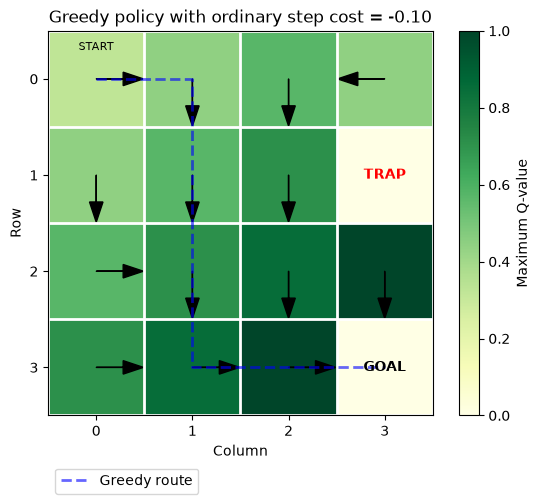

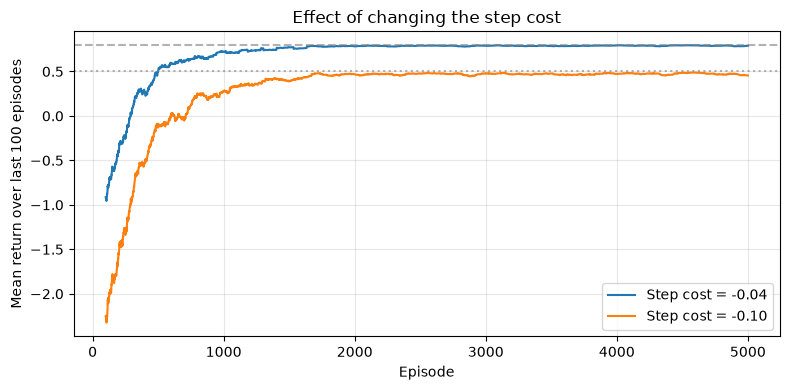

In [10]:
CHANGED_STEP_COST = -0.10

(
    Q_changed,
    changed_training_returns,
    changed_epsilon_history,
    changed_final_epsilon,
) = train_q_learning(step_cost=CHANGED_STEP_COST)

changed_results = evaluate_policy(
    Q_changed,
    step_cost=CHANGED_STEP_COST,
)

print("Changed step cost:", CHANGED_STEP_COST)
print("Success rate:", f"{changed_results['success_rate']:.1%}")
print("Mean return:", round(changed_results["mean_return"], 3))
print("Mean moves:", changed_results["mean_moves"])

print("\nChanged greedy route:")
print(" -> ".join(map(str, changed_results["path"])))

plot_policy(
    Q_changed,
    "Greedy policy with ordinary step cost = -0.10",
    path=changed_results["path"],
)

changed_moving = np.convolve(
    changed_training_returns,
    np.ones(window) / window,
    mode="valid",
)

plt.figure(figsize=(8, 4))

plt.plot(
    np.arange(window, len(training_returns) + 1),
    moving_returns,
    label="Step cost = -0.04",
)

plt.plot(
    np.arange(window, len(changed_training_returns) + 1),
    changed_moving,
    label="Step cost = -0.10",
)

plt.axhline(0.80, linestyle="--", color="gray", alpha=0.6)
plt.axhline(0.50, linestyle=":", color="gray", alpha=0.6)

plt.xlabel("Episode")
plt.ylabel("Mean return over last 100 episodes")
plt.title("Effect of changing the step cost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Lab 6: Reinforcement Learning

## Part A: Tabular Q-learning in GridWorld

The agent learned to navigate a 4 × 4 grid from the starting state **(0, 0)** to the goal **(3, 3)** while avoiding the trap at **(1, 3)**.

The available actions were up, down, left, and right. Ordinary moves received a reward of **−0.04**, reaching the goal received **+1**, and entering the trap received **−1**. Entering either the goal or trap ended the episode. Actions beyond the grid boundary left the position unchanged.

### Training Settings

| Setting | Value |
|---|---:|
| Training episodes | 5,000 |
| Maximum moves per episode | 100 |
| Learning rate α | 0.15 |
| Discount factor γ | 0.95 |
| Initial exploration probability ε | 1.0 |
| Exploration decay multiplier | 0.9985 |
| Minimum exploration probability | 0.05 |

The Q-table was initialized with zeros. During training, the agent used an epsilon-greedy policy: it sometimes explored randomly and otherwise selected the action with the highest current Q-value.

The smoothed training return increased from negative values toward 0.80 as the agent learned. Exploration decreased to its minimum of 0.05 at approximately 2,000 episodes. Training returns remained slightly below the best possible return because random exploration continued to cause occasional unnecessary moves or failures.

### Greedy Policy Evaluation

The final policy was evaluated for **200 episodes with exploration disabled**.

| Metric | Result |
|---|---:|
| Success rate | 100% |
| Mean episode return | 0.80 |
| Mean number of moves | 6 |

The learned route was:

**(0, 0) → (1, 0) → (2, 0) → (2, 1) → (3, 1) → (3, 2) → (3, 3)**

This route avoided the trap and reached the goal in six moves. Six moves is the shortest possible route because reaching (3, 3) from (0, 0) requires at least three downward and three rightward moves.

The final move receives the goal reward instead of an ordinary move cost. Therefore, the undiscounted episode return was:

**5(−0.04) + 1 = 0.80**

The environment and greedy policy are deterministic, so repeated evaluation from the same starting state followed the same route. These 200 evaluations confirm the behavior of this trained policy, but do not measure variation across independent training seeds.

## Part B: Saving and Reading the Policy

The learned Q-table was saved as **models/gridworld_q_table.npy** and reloaded successfully. The reloaded table exactly matched the original table.

The policy read from the reloaded table was:

| Row / Column | 0 | 1 | 2 | 3 |
|---|---|---|---|---|
| 0 | Down | Down | Down | Left |
| 1 | Down | Down | Down | TRAP |
| 2 | Right | Down | Down | Down |
| 3 | Right | Right | Right | GOAL |

The reloaded policy achieved **100% success** and a **mean return of 0.80**, confirming that the saved table preserved the learned behavior without retraining.

The policy plot shows actions leading toward the goal while avoiding the trap. Maximum Q-values generally increase closer to the goal along safe routes because fewer move penalties and less discounting separate those states from the positive terminal reward.

The goal and trap have zero stored outgoing Q-values because episodes terminate when they are entered. Their rewards are represented in the values of actions leading into them.

## Try It Yourself: Changing the Step Cost

The ordinary step cost was changed from **−0.04 to −0.10**, while the other training settings remained unchanged. A new Q-table was trained from scratch.

### Prediction and Results

The prediction was that a shortest safe route would remain optimal, but the larger movement penalty would reduce returns and learned values.

| Setting | Original model | Changed step cost |
|---|---:|---:|
| Ordinary move reward | −0.04 | −0.10 |
| Evaluation episodes | 200 | 200 |
| Success rate | 100% | 100% |
| Mean moves | 6 | 6 |
| Mean return | 0.80 | 0.50 |

The changed model followed this route:

**(0, 0) → (0, 1) → (1, 1) → (2, 1) → (3, 1) → (3, 2) → (3, 3)**

The exact route changed, but both routes avoided the trap and reached the goal in six moves. Several equally short safe routes exist, so a different selected route does not necessarily indicate a better policy.

The changed return was:

**5(−0.10) + 1 = 0.50**

This matched the prediction. The larger penalty made unnecessary movement more costly and reduced values along the route. However, it did not reduce the evaluated route length because the original policy already used the minimum number of moves.

The changed model's training curve also settled at a lower return. These curves use different reward rules, so their different heights should not be interpreted as a direct difference in navigation success.

## Check Your Understanding

### 1. What are the state, action, reward, and transition in a reinforcement-learning formulation?

- **State:** The information describing the agent's current situation. In this lab, it is the current grid position, such as (0, 0).
- **Action:** A choice available to the agent. Here, the choices are up, down, left, and right.
- **Reward:** The numerical feedback received after an action. Here, ordinary moves receive a negative cost, the goal gives +1, and the trap gives −1.
- **Transition:** The rule determining the next state after an action. Here, movement changes the grid position unless a boundary prevents it.

### 2. What two pieces of information appear in the tabular Q-learning backup value?

For a nonterminal transition, the backup combines:

1. The immediate reward received after the action.
2. The discounted maximum estimated Q-value available at the next state.

The backup is:

**Target = reward + γ × max Q(next state, action)**

For a terminal transition, the target is only the immediate reward because there are no further actions in that episode.

The update moves the current estimate toward this target:

**New Q = Old Q + α × (Target − Old Q)**

The reported episode returns are undiscounted reward sums, while the Q-learning updates use γ = 0.95 to discount future rewards.

### 3. Why should the exploratory training policy be evaluated separately from the final greedy policy?

The training policy deliberately takes random actions to discover useful behavior. These exploratory actions can cause extra moves or entry into the trap even after good Q-values have been learned.

The final greedy policy selects the highest-valued action without random exploration. Evaluating it separately measures the behavior intended for deployment, rather than combining learned performance with the cost of exploration.

In this experiment, training returns remained slightly below the best possible return, while the greedy policy consistently reached the goal in six moves with a return of 0.80.